# Notebook 2 — Dataset de predictores y target

**Objetivo.** Construir el dataset de modelado: seleccionar las variables predictoras de ypN (afectación ganglionar axilar tras terapia neoadyuvante) y definir el target binario (ypN0 frente a ypN+). **Momento de inferencia:** tras la neoadyuvancia y **antes de la cirugía**, por lo que solo se usan variables disponibles en ese momento y se excluye todo lo que se conoce después de operar.

**Entradas**
- `data/tabla_clinica_agregada.csv`: 85 pacientes (con PET-CT, sin metástasis a distancia), salida del notebook 1.

**Salidas**
- `data/dataset_modelado.csv`: predictoras + `ypN` + `ypN_binario`.

**Criterios de selección**
1. Tratamientos con menos de 10 pacientes o constantes → excluir.
2. `taxano` (95,3 %) → excluir por baja variabilidad.
3. Variables constantes tras filtrar la cohorte (M, sexo, tipo de cáncer, población, centro) → excluir.
4. Variables posteriores a la cirugía (ypT, fallecimiento, recurrencia) → excluir por fuga de información.
5. Fechas → excluir (no son predictores clínicos).

**Aislamiento / no data leakage.** Aquí solo se eliminan variables por criterio clínico y de variabilidad, sin ajustar nada con los datos de evaluación. Los valores perdidos **no se imputan** en este notebook: se dejan tal cual y se imputan dentro de cada fold de la validación cruzada.

Criterios aplicados:
  1. Variables de tratamiento con <10 casos positivos o constantes -> EXCLUIR
  2. 'taxano' (95.3% positivos) -> EXCLUIR por baja variabilidad
  3. Variables constantes sin valor predictivo -> EXCLUIR

Parte de data/tabla_clinica_agregada.csv (N=85, ya con exclusión
de pacientes sin imagen y de M1) y aplica los criterios de selección de
variables acordados, generando el dataset final listo para la fase de
modelado.

In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, mannwhitneyu, skew

In [2]:
CARPETA_DATA = "data"
CARPETA_FIG = "fig"
CARPETA_RESULTADOS = "results"
TARGET_BIN = "ypN_binario"

os.makedirs(CARPETA_FIG, exist_ok=True)
os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

In [3]:
# --- Decisiones de transformación (interruptores) ---
UNIR_HISTOLOGIA = True            # ductal frente a otra (lobular y sin especificar tienen <10 pacientes)
EXCLUIR_PR_SI_DUPLICADA = True    # excluye PR solo si es idéntica a ER (comprobado en la sección 5.3)
UMBRAL_RARA = 10                  # pacientes mínimos por categoría
EXCLUIR_ANTI_HER2 = True # excluye anti_HER2 y ciclos_anti_HER2 (casi idénticas a HER2 positivo)
EXCLUIR_DELTA_TLG = True     # derivada de ΔMTV (TLG = MTV x SUVmean); correlación 0.968

**Sección 1.** Carga de la tabla agregada

In [4]:
# 1. Carga de datos
df = pd.read_csv("data/tabla_clinica_agregada.csv")
print(f"Shape de entrada: {df.shape}")

Shape de entrada: (85, 43)


**Sección 2.** Definición de las variables a excluir (tratamiento, fuga, constantes y fechas)

**Filtro 1 — Exclusiones a priori / Diseño experimental (antiguo Notebook 2):Variables post-quirúrgicas (evitar data leakage: ypT, fallecimiento, recurrencia).   Metadatos y fechas sin valor predictivo.   Variables constantes o con $N < 10$ en la cohorte $N=85$ (taxano, hormonoterapia, etc.).   (Paso a 21 predictoras intermedias).**

Se excluyen variables por criterios clínicos / diseño previo: leakage quirúrgico (ypT, supervivencia), variables constantes (M, Cancer type, sexo), fechas y tratamientos sin variabilidad mínima ($<10$ casos como inmunoterapia o $>95\%$ como taxano).   

Criterio: menos de 10 pacientes (insuficientes con N=85 y unos 30 ypN+) o más del 95 % (casi constante).
Está escrita a mano: si se añade una familia de fármacos nueva, hay que revisarla con la tabla de
 recomendaciones del notebook 1.

In [5]:
# --- Variables de tratamiento a excluir (baja variabilidad / insuficientes) ---
CATEGORIAS_A_EXCLUIR = [
    'taxano', 'hormonoterapia', 'inhibidor_CDK46',
    'inmunoterapia', 'ipatasertib', 'soporte_GCSF',
    'alquilante',   # idéntica a 'antraciclina' en los 76 pacientes que la reciben (régimen EC/AC, mismos ciclos)

    #Ambos fármacos se administran el mismo día y durante los mismos ciclos. Si una paciente recibe EC o AC, recibe los dos.
    #Por eso las columnas antraciclina y alquilante valen lo mismo en las 76 pacientes que las recibieron, y también el número de ciclos.
]
columnas_tratamiento_excluir = CATEGORIAS_A_EXCLUIR + [f'ciclos_{c}' for c in CATEGORIAS_A_EXCLUIR]

In [6]:

# --- Variables con riesgo de fuga de información (LEAKAGE) ---
columnas_leakage = [
    'ypT',                                          # Target secundario / simultáneo a cirugía
    'Surgery type', 'Surgery location', 'Surgery date', 
    'Patient death', 'Recurrence',
]

Todo lo que se conoce DESPUÉS de operar queda fuera. ypT es el resultado patológico de la misma
cirugía que define ypN; fallecimiento y recurrencia ocurren más tarde. Las variables de respuesta
RECIST y los Delta PET-CT se miden tras la neoadyuvancia y antes de la cirugía, por eso SÍ se mantienen.
Las columnas 'Surgery ...' no existen en esta tabla; se listan como red de seguridad.

In [7]:
# --- Variables constantes / sin valor predictivo ---
columnas_constantes = ['Population', 'Site', 'M', 'Patient sex', 'Cancer type']
# Tras filtrar la cohorte (solo M0, solo mujeres, un único tipo de cáncer, población y centro únicos) no varían.

In [8]:
# --- Fechas ---
columnas_fecha = [
    'Date of diagnosis', 'Date of biopsy for diagnosis',
    'Date of PET-CT study for diagnosis', 'Systemic therapy start date',
    'Date of PET-CT study for treatment evaluation'
]
# Las fechas no son predictores clínicos y, además, dan información temporal que puede filtrar el desenlace.

In [9]:
# Consolidación de exclusiones
todas_las_exclusiones = (
    columnas_tratamiento_excluir + 
    columnas_leakage + 
    columnas_constantes + 
    columnas_fecha
)

In [10]:
columnas_a_excluir_existentes = [c for c in todas_las_exclusiones if c in df.columns]

In [11]:
print(f"\n[EXCLUSIONES] Total columnas a excluir identificadas ({len(columnas_a_excluir_existentes)}):")
for c in columnas_a_excluir_existentes:
    motivo = "LEAKAGE" if c in columnas_leakage else "BAJA VAR / CONSTANTE / FECHA"
    print(f"  - [{motivo}] {c}")


[EXCLUSIONES] Total columnas a excluir identificadas (20):
  - [BAJA VAR / CONSTANTE / FECHA] taxano
  - [BAJA VAR / CONSTANTE / FECHA] hormonoterapia
  - [BAJA VAR / CONSTANTE / FECHA] inhibidor_CDK46
  - [BAJA VAR / CONSTANTE / FECHA] inmunoterapia
  - [BAJA VAR / CONSTANTE / FECHA] ipatasertib
  - [BAJA VAR / CONSTANTE / FECHA] soporte_GCSF
  - [BAJA VAR / CONSTANTE / FECHA] alquilante
  - [BAJA VAR / CONSTANTE / FECHA] ciclos_taxano
  - [BAJA VAR / CONSTANTE / FECHA] ciclos_hormonoterapia
  - [BAJA VAR / CONSTANTE / FECHA] ciclos_inhibidor_CDK46
  - [BAJA VAR / CONSTANTE / FECHA] ciclos_inmunoterapia
  - [BAJA VAR / CONSTANTE / FECHA] ciclos_ipatasertib
  - [BAJA VAR / CONSTANTE / FECHA] ciclos_soporte_GCSF
  - [BAJA VAR / CONSTANTE / FECHA] ciclos_alquilante
  - [LEAKAGE] ypT
  - [LEAKAGE] Patient death
  - [LEAKAGE] Recurrence
  - [BAJA VAR / CONSTANTE / FECHA] M
  - [BAJA VAR / CONSTANTE / FECHA] Patient sex
  - [BAJA VAR / CONSTANTE / FECHA] Cancer type


**Sección 3.** Selección de las predictoras finales

In [12]:
# --- Target principal ---
TARGET = 'ypN'

In [13]:
# Selección de predictoras finales
columnas_predictoras = [
    c for c in df.columns 
    if c not in columnas_a_excluir_existentes and c != TARGET and c != 'Patient ID'
]

In [14]:
print(f"\n[PREDICTORES] Columnas predictoras intermedias ({len(columnas_predictoras)}):")
for c in columnas_predictoras:
    print(f"  - {c}")


[PREDICTORES] Columnas predictoras intermedias (21):
  - Age at diagnosis
  - Tumor histology
  - HER2 (presence)
  - ER (presence)
  - PR (presence)
  - Ki-67
  - Size of primary lesion
  - T
  - N
  - SUV max (at diagnosis)
  - Systemic therapy breast response (RECIST)
  - Systemic therapy axillar response (RECIST)
  - Delta SUV max
  - Delta TLG
  - Delta MTV
  - antraciclina
  - ciclos_antraciclina
  - platino
  - ciclos_platino
  - anti_HER2
  - ciclos_anti_HER2


ypN+ incluye ypN1mi (micrometástasis, 6 pacientes), ypN1 y ypN2. Se trata cualquier afectación ganglionar
residual como positiva: clínicamente es la que obliga a seguir tratando la axila.

In [15]:
# Construcción de la tabla de modelado
df_modelado = df[['Patient ID'] + columnas_predictoras + [TARGET]].copy()

**Sección 4. Target binario (ypN0 frente a ypN+)**

In [16]:
# --- Target binarizado (ypN0 vs ypN+) ---
df_modelado[TARGET] = df_modelado[TARGET].astype(str).str.strip()
df_modelado[f'{TARGET}_binario'] = df_modelado[TARGET].apply(lambda x: 0 if x == 'ypN0' else 1)

print("\n" + "="*50)
print("DISTRIBUCIÓN DE TARGET")
print("="*50)
print(f"Target binarizado ({TARGET}_binario):")
counts_bin = df_modelado[f'{TARGET}_binario'].value_counts()
pcts_bin = df_modelado[f'{TARGET}_binario'].value_counts(normalize=True) * 100
for val in counts_bin.index:
    etiqueta = "ypN0 (Respuesta Completa)" if val == 0 else "ypN+ (Afectación Residual)"
    print(f"  Clase {val} [{etiqueta}]: {counts_bin[val]} casos ({pcts_bin[val]:.1f}%)")


DISTRIBUCIÓN DE TARGET
Target binarizado (ypN_binario):
  Clase 0 [ypN0 (Respuesta Completa)]: 55 casos (64.7%)
  Clase 1 [ypN+ (Afectación Residual)]: 30 casos (35.3%)


In [17]:
print(f"\nCategorías originales de {TARGET}:")
print(df_modelado[TARGET].value_counts())


Categorías originales de ypN:
ypN
ypN0      55
ypN2      13
ypN1      11
ypN1mi     6
Name: count, dtype: int64


In [18]:
# Limpieza de espacios en las columnas de texto
for c in df_modelado.select_dtypes(exclude=['number', 'bool']).columns:
    df_modelado[c] = df_modelado[c].str.strip()

assert len(df_modelado) == df['Patient ID'].nunique() == 85
assert not set(columnas_predictoras) & set(columnas_leakage)

df_modelado.to_csv("data/dataset_modelado.csv", index=False)
print("[OK] dataset_modelado.csv:", df_modelado.shape)

[OK] dataset_modelado.csv: (85, 24)


**Sección 5.** Análisis exploratorio de los datos (EDA)

**Filtro 2 — Exclusiones estadísticas:PR (presence): descartada por ser 100% idéntica a ER (presence) en esta muestra (ahorra redundancia estricta).   anti_HER2 y ciclos_anti_HER2: descartadas por colinealidad biológica directa con el estado tumoral HER2 (presence).   Delta TLG: descartada por derivación volumétrica ($TLG = MTV \times SUV_{mean}$) con correlación de Spearman $\rho = 0.968$ frente a Delta MTV.   (Paso a las 17 predictoras finales numéricas).**

Se excluyen por criterios estadísticos / colinealidad matemática: duplicidad 1:1 (ER vs PR), colinealidad de indicación médica (HER2 positivo vs recibir anti_HER2) y correlación de imagen redundante (Delta TLG con Delta MTV, $\rho = 0.968$).  

**5.1 Variables numéricas: distribución, asimetría y valores atípicos**

In [19]:
# A partir de aquí, df = tabla de modelado (ya con ypN_binario). La tabla original queda atrás.
df = df_modelado.copy()

NO_PREDICTORAS = ['Patient ID', 'ypN', TARGET_BIN]
predictoras = [c for c in df.columns if c not in NO_PREDICTORAS]
assert predictoras == columnas_predictoras

bin_cols  = [c for c in predictoras if pd.api.types.is_bool_dtype(df[c])]
cat_cols  = [c for c in predictoras if c not in bin_cols and not pd.api.types.is_numeric_dtype(df[c])]
ciclos    = [c for c in predictoras if c.startswith('ciclos_')]
num_cols  = [c for c in predictoras if c not in cat_cols + bin_cols + ciclos]
assert len(bin_cols) == 3 and len(cat_cols) == 7

print(f"Predictoras ({len(predictoras)}):")
print("Categóricas :", cat_cols)
print("Binarias    :", bin_cols)
print("Ciclos      :", ciclos)
print("Numéricas   :", num_cols)
print("\nTarget:", df[TARGET_BIN].value_counts().to_dict(), f"({100*df[TARGET_BIN].mean():.1f}% ypN+)")

Predictoras (21):
Categóricas : ['Tumor histology', 'HER2 (presence)', 'ER (presence)', 'PR (presence)', 'Ki-67', 'Systemic therapy breast response (RECIST)', 'Systemic therapy axillar response (RECIST)']
Binarias    : ['antraciclina', 'platino', 'anti_HER2']
Ciclos      : ['ciclos_antraciclina', 'ciclos_platino', 'ciclos_anti_HER2']
Numéricas   : ['Age at diagnosis', 'Size of primary lesion', 'T', 'N', 'SUV max (at diagnosis)', 'Delta SUV max', 'Delta TLG', 'Delta MTV']

Target: {0: 55, 1: 30} (35.3% ypN+)


              variable  n  media     de  mediana  minimo  maximo  asimetria  atipicos_IQR
      Age at diagnosis 85  50.74  11.48    49.00   25.00   81.00       0.56             1
Size of primary lesion 85   3.22   2.41     2.40    0.70   13.00       2.26             6
                     T 85   2.05   0.79     2.00    1.00    4.00       0.66            37
                     N 85   1.32   0.79     1.00    0.00    3.00       1.13            25
SUV max (at diagnosis) 85  12.42   8.67    10.13    1.60   44.79       1.42             3
         Delta SUV max 71   9.38   8.15     7.30   -0.10   42.16       1.81             2
             Delta TLG 54 144.09 336.33    34.10    1.15 2317.49       5.26             6
             Delta MTV 54  23.75  61.28     5.62   -0.13  435.02       5.81             6


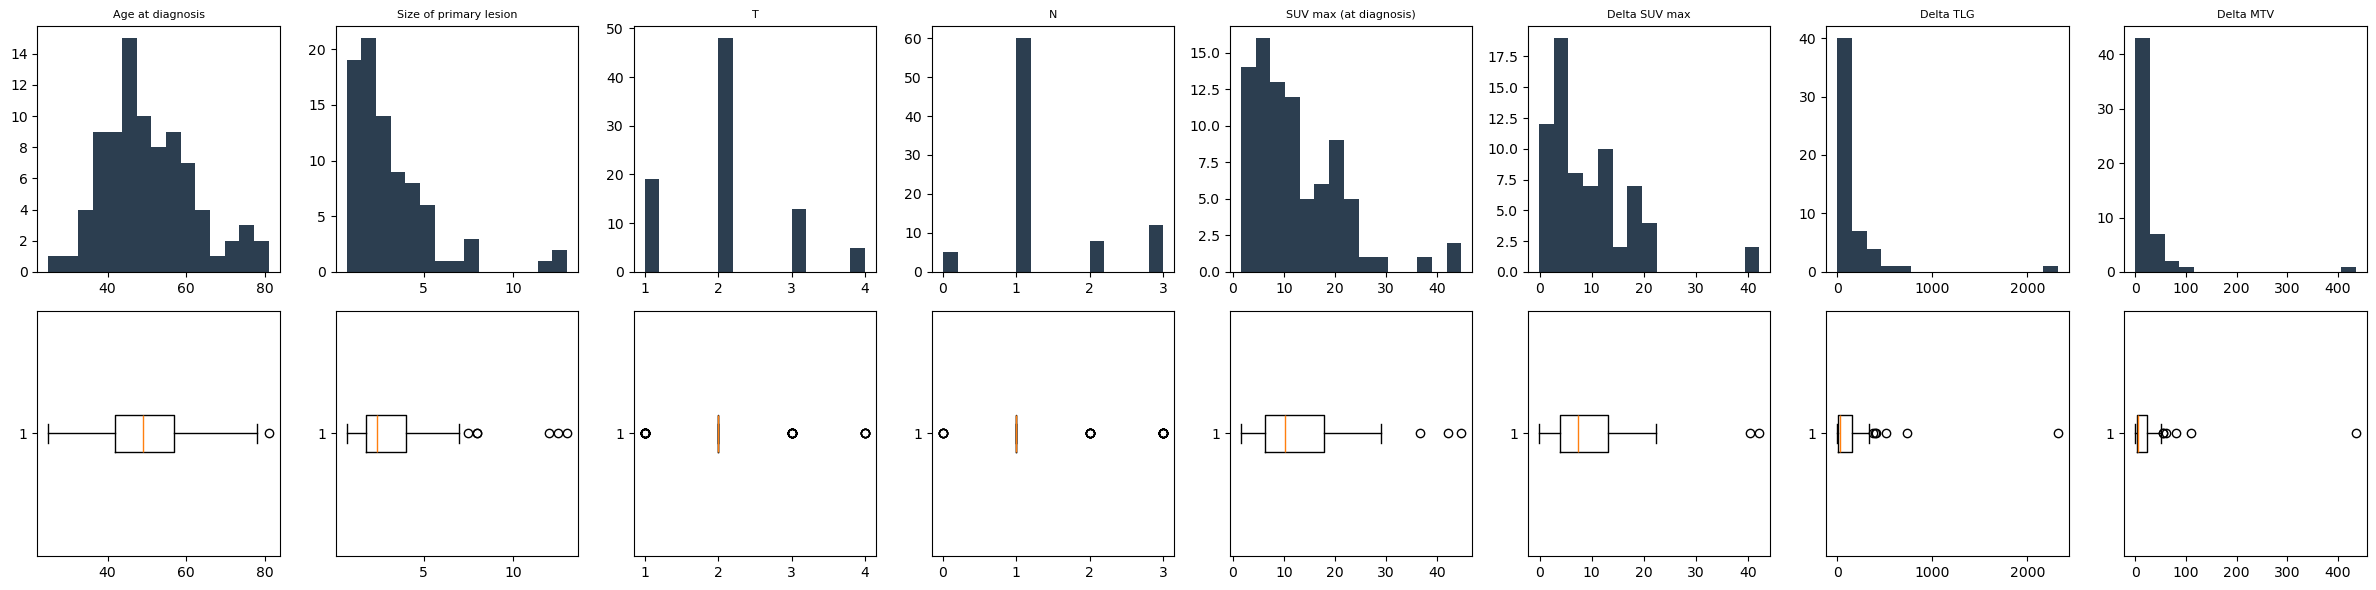

In [20]:
filas = []
for c in num_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    atip = int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())
    filas.append(dict(variable=c, n=len(s), media=s.mean(), de=s.std(), mediana=s.median(),
                      minimo=s.min(), maximo=s.max(), asimetria=skew(s), atipicos_IQR=atip))
desc_num = pd.DataFrame(filas).round(2)
print(desc_num.to_string(index=False))

fig, axs = plt.subplots(2, len(num_cols), figsize=(3*len(num_cols), 6))
for j, c in enumerate(num_cols):
    s = df[c].dropna()
    axs[0, j].hist(s, bins=15, color='#2c3e50'); axs[0, j].set_title(c, fontsize=8)
    axs[1, j].boxplot(s, vert=False)
plt.tight_layout()
plt.savefig(f"{CARPETA_FIG}/eda_numericas.png", dpi=200, bbox_inches='tight')
plt.show()

5.2 **Valores ausentes y patrones de ausencia**

In [21]:
nulos = df[predictoras].isna().sum()
tabla_nulos = pd.DataFrame({'n_nulos': nulos, 'pct': (100*nulos/len(df)).round(1)})
print(tabla_nulos[tabla_nulos.n_nulos > 0])

# ¿Faltan en las mismas pacientes?
con_nulos = [c for c in predictoras if nulos[c] > 0]
patrones = df[con_nulos].isna().astype(int).astype(str).agg(''.join, axis=1)
print("\nPatrones de ausencia (orden de columnas:", con_nulos, ")")
print(patrones.value_counts())

                 n_nulos   pct
HER2 (presence)        1   1.2
ER (presence)          1   1.2
PR (presence)          1   1.2
Ki-67                  1   1.2
Delta SUV max         14  16.5
Delta TLG             31  36.5
Delta MTV             31  36.5

Patrones de ausencia (orden de columnas: ['HER2 (presence)', 'ER (presence)', 'PR (presence)', 'Ki-67', 'Delta SUV max', 'Delta TLG', 'Delta MTV'] )
0000000    53
0000011    17
0000111    14
1111000     1
Name: count, dtype: int64


La cadena de dígitos de la izquierda tiene 7 posiciones, una por cada variable que tiene algún valor ausente, en este orden:

HER2
ER
PR
Ki-67
ΔSUVmax
ΔTLG
ΔMTV

Un 0 significa que el dato está presente y un 1 que falta.

5.3 **Redundancia entre variables (incluidas las categóricas)**

In [22]:
# Matriz provisional: one-hot sin tocar nada, solo para detectar duplicados y asociaciones
tmp = df[predictoras].copy()
tmp_enc = pd.get_dummies(tmp, columns=cat_cols, drop_first=False, dtype=float)
for c in bin_cols:
    tmp_enc[c] = tmp_enc[c].astype(float)

In [23]:

# a) Columnas idénticas
dup = tmp_enc.T.duplicated(keep=False)
grupos = {}
for c in tmp_enc.columns[dup]:
    clave = tuple(tmp_enc[c].fillna(-999).values)
    grupos.setdefault(clave, []).append(c)
print("Columnas idénticas (grupos):")
for g in grupos.values():
    print("  ", g)

Columnas idénticas (grupos):
   ['ER (presence)_negative', 'PR (presence)_negative']
   ['ER (presence)_positive', 'PR (presence)_positive']


In [24]:
# b) Pares con |Spearman| > 0.9
corr = tmp_enc.corr(method='spearman').abs()
origen = {col: next((v for v in cat_cols if col.startswith(v + "_")), col) for col in tmp_enc.columns}
pares = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(corr.columns)
         for b in corr.columns[i+1:] if corr.loc[a, b] > 0.9 and origen[a] != origen[b]]
print("\nPares con |Spearman| > 0.9 entre variables distintas (binaria-ciclos es esperable):")
for p in pares:
    print("  ", p)


Pares con |Spearman| > 0.9 entre variables distintas (binaria-ciclos es esperable):
   ('Delta TLG', 'Delta MTV', np.float64(0.968))
   ('platino', 'ciclos_platino', np.float64(0.988))
   ('anti_HER2', 'ciclos_anti_HER2', np.float64(0.995))
   ('anti_HER2', 'HER2 (presence)_negative', np.float64(0.947))
   ('anti_HER2', 'HER2 (presence)_positive', np.float64(0.973))
   ('ciclos_anti_HER2', 'HER2 (presence)_negative', np.float64(0.943))
   ('ciclos_anti_HER2', 'HER2 (presence)_positive', np.float64(0.97))
   ('ER (presence)_negative', 'PR (presence)_negative', np.float64(1.0))
   ('ER (presence)_negative', 'PR (presence)_positive', np.float64(0.972))
   ('ER (presence)_positive', 'PR (presence)_negative', np.float64(0.972))
   ('ER (presence)_positive', 'PR (presence)_positive', np.float64(1.0))


In [25]:
# c) ER frente a PR y HER2 frente a anti-HER2
print("\nER frente a PR:")
print(pd.crosstab(df['ER (presence)'].fillna('NA'), df['PR (presence)'].fillna('NA')))
print("\nHER2 frente a anti_HER2:")
print(pd.crosstab(df['HER2 (presence)'].fillna('NA'), df['anti_HER2']))
print("\nHER2 frente a platino:")
print(pd.crosstab(df['HER2 (presence)'].fillna('NA'), df['platino']))

ER_IGUAL_PR = bool((df['ER (presence)'].fillna('NA') == df['PR (presence)'].fillna('NA')).all())
print("\nER == PR en todas las pacientes:", ER_IGUAL_PR)


ER frente a PR:
PR (presence)  NA  negative  positive
ER (presence)                        
NA              1         0         0
negative        0        25         0
positive        0         0        59

HER2 frente a anti_HER2:
anti_HER2        False  True 
HER2 (presence)              
NA                   1      0
negative            56      1
positive             0     27

HER2 frente a platino:
platino          False  True 
HER2 (presence)              
NA                   0      1
negative            37     20
positive            27      0

ER == PR en todas las pacientes: True


5.4 **Variables categóricas y binarias: frecuencias y categorías raras**

In [26]:
raras = []
for c in cat_cols + bin_cols:
    vc = df[c].value_counts(dropna=False)
    print(f"\n{c}")
    print(vc.to_string())
    for nivel, n in vc.items():
        if n < 10:
            raras.append((c, nivel, int(n)))
print(f"\nCategorías con menos de {10} pacientes:")
for r in raras:
    print("  ", r)


Tumor histology
Tumor histology
invasive ductal carninoma of breast          76
invasive carcinoma of breast, unspecified     6
invasive lobular carcinoma of breast          3

HER2 (presence)
HER2 (presence)
negative    57
positive    27
NaN          1

ER (presence)
ER (presence)
positive    59
negative    25
NaN          1

PR (presence)
PR (presence)
positive    59
negative    25
NaN          1

Ki-67
Ki-67
high    77
low      7
NaN      1

Systemic therapy breast response (RECIST)
Systemic therapy breast response (RECIST)
complete response    43
partial response     42

Systemic therapy axillar response (RECIST)
Systemic therapy axillar response (RECIST)
complete response    62
partial response     23

antraciclina
antraciclina
True     76
False     9

platino
platino
False    64
True     21

anti_HER2
anti_HER2
False    57
True     28

Categorías con menos de 10 pacientes:
   ('Tumor histology', 'invasive carcinoma of breast, unspecified', 6)
   ('Tumor histology', 'invasive lob

5.5 Variables de tratamiento: coherencia entre la binaria y los ciclos

In [27]:
 for fam in ['antraciclina', 'platino', 'anti_HER2']:
    cic = f'ciclos_{fam}'
    recibio = df[fam].astype(bool)
    print(f"\n{fam}: recibió={recibio.sum()} | ciclos>0={int((df[cic] > 0).sum())} | "
          f"incoherentes (ciclos>0 sin recibir o recibir sin ciclos): "
          f"{int(((df[cic] > 0) != recibio).sum())}")
    print(df.loc[recibio, cic].describe().round(2).to_string())


antraciclina: recibió=76 | ciclos>0=76 | incoherentes (ciclos>0 sin recibir o recibir sin ciclos): 0
count    76.00
mean      4.04
std       1.03
min       2.00
25%       4.00
50%       4.00
75%       4.00
max      12.00

platino: recibió=21 | ciclos>0=21 | incoherentes (ciclos>0 sin recibir o recibir sin ciclos): 0
count    21.00
mean      9.90
std       4.13
min       3.00
25%       7.00
50%      12.00
75%      12.00
max      21.00

anti_HER2: recibió=28 | ciclos>0=28 | incoherentes (ciclos>0 sin recibir o recibir sin ciclos): 0
count    28.00
mean      4.57
std       2.66
min       4.00
25%       4.00
50%       4.00
75%       4.00
max      18.00


5.6    $\Delta\text{SUVmax}$, estadios T y N

In [28]:
d = df[['SUV max (at diagnosis)', 'Delta SUV max']].dropna()
print("ΔSUVmax <= SUVmax basal en todas:", bool((d['Delta SUV max'] <= d['SUV max (at diagnosis)']).all()))
print("Pacientes con ΔSUVmax < 0:", int((df['Delta SUV max'] < 0).sum()),
      "| ΔTLG < 0:", int((df['Delta TLG'] < 0).sum()), "| ΔMTV < 0:", int((df['Delta MTV'] < 0).sum()))
print("\nΔSUVmax / SUVmax basal x 100 (si el Δ fuera absoluto, iría de 0 a 100):")
print((100 * d['Delta SUV max'] / d['SUV max (at diagnosis)']).describe().round(1).to_string())
print("\nTamaño de la lesión por T:")
print(df.groupby('T')['Size of primary lesion'].describe().round(2).to_string())
print("\nValores de T:", sorted(df['T'].dropna().unique()), "| valores de N:", sorted(df['N'].dropna().unique()))

ΔSUVmax <= SUVmax basal en todas: True
Pacientes con ΔSUVmax < 0: 1 | ΔTLG < 0: 0 | ΔMTV < 0: 1

ΔSUVmax / SUVmax basal x 100 (si el Δ fuera absoluto, iría de 0 a 100):
count     71.0
mean      74.3
std       24.7
min       -6.2
25%       67.2
50%       80.2
75%       91.1
max      100.0

Tamaño de la lesión por T:
     count  mean   std  min   25%  50%   75%   max
T                                                 
1.0   19.0  1.75  1.55  0.7  1.30  1.4  1.65   8.0
2.0   48.0  2.93  1.30  0.8  2.08  2.6  3.42   8.0
3.0   13.0  5.52  3.66  1.1  2.80  5.2  7.00  13.0
4.0    5.0  5.64  3.89  2.9  4.00  4.0  4.80  12.5

Valores de T: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)] | valores de N: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]


5.7 Asociación descriptiva con ypN (tablas cruzadas, Fisher, Mann-Whitney y nulos por clase)

In [29]:
filas = []
for c in cat_cols + bin_cols:
    for nivel, g in df.groupby(df[c].fillna('NA')):
        filas.append(dict(variable=c, nivel=nivel, n=len(g), ypN_pos=int(g[TARGET_BIN].sum()),
                          pct_ypN_pos=round(100*g[TARGET_BIN].mean(), 1)))
rel_cat = pd.DataFrame(filas)
print(rel_cat.to_string(index=False))

                                  variable                                     nivel  n  ypN_pos  pct_ypN_pos
                           Tumor histology invasive carcinoma of breast, unspecified  6        2         33.3
                           Tumor histology       invasive ductal carninoma of breast 76       27         35.5
                           Tumor histology      invasive lobular carcinoma of breast  3        1         33.3
                           HER2 (presence)                                        NA  1        0          0.0
                           HER2 (presence)                                  negative 57       30         52.6
                           HER2 (presence)                                  positive 27        0          0.0
                             ER (presence)                                        NA  1        0          0.0
                             ER (presence)                                  negative 25        5         20.0
          

In [30]:
print(df.shape)
print('ypN_binario' in df.columns)
print('ypN_binario' in df_modelado.columns)

(85, 24)
True
True


In [31]:

filas = []
for c in num_cols + ciclos:
    a = df.loc[df[TARGET_BIN] == 0, c].dropna(); b = df.loc[df[TARGET_BIN] == 1, c].dropna()
    filas.append(dict(variable=c, mediana_ypN0=a.median(), mediana_ypN_pos=b.median(),
                      p_MannWhitney=mannwhitneyu(a, b).pvalue))
rel_num = pd.DataFrame(filas).round(4)
print("\n", rel_num.to_string(index=False))

print("\nValores ausentes de los Δ frente a ypN (¿informativa la ausencia?):")
for c in ['Delta SUV max', 'Delta TLG', 'Delta MTV']:
    print(pd.crosstab(df[c].isna().rename(f'{c} ausente'), df[TARGET_BIN]), '\n')


               variable  mediana_ypN0  mediana_ypN_pos  p_MannWhitney
      Age at diagnosis        47.000           54.000         0.0644
Size of primary lesion         2.300            2.700         0.4699
                     T         2.000            2.000         0.3537
                     N         1.000            1.000         0.0456
SUV max (at diagnosis)        11.260            9.265         0.2485
         Delta SUV max         9.310            4.615         0.0175
             Delta TLG        25.695           53.255         0.7269
             Delta MTV         5.205            9.365         0.3753
   ciclos_antraciclina         4.000            4.000         0.2303
        ciclos_platino         0.000            0.000         0.2147
      ciclos_anti_HER2         0.000            0.000         0.0000

Valores ausentes de los Δ frente a ypN (¿informativa la ausencia?):
ypN_binario             0   1
Delta SUV max ausente        
False                  43  28
True       

Entre las variables numéricas, la mayor diferencia entre ypN0 y ypN+ se observa en ΔSUVmax (mediana 9,31 frente a 4,62; p = 0,018), es decir, una mayor reducción de la captación en las pacientes sin afectación ganglionar residual. N (p = 0,046) y la edad (47 frente a 54 años; p = 0,064) muestran una asociación débil, y el resto de variables no presenta diferencias apreciables. ciclos_anti_HER2 (p < 0,001) refleja el estado HER2, ya que solo lo reciben las pacientes HER2 positivas. Respecto a los valores ausentes, ΔSUVmax falta en 12 de las 55 pacientes ypN0 (21,8 %) y en 2 de las 30 ypN+ (6,7 %), mientras que ΔTLG y ΔMTV faltan en 21 (38,2 %) y 10 (33,3 %), respectivamente. No hay indicios claros de que la ausencia dependa del resultado, aunque con tan pocos casos el análisis tiene poca potencia. Los valores p no se corrigen por comparaciones múltiples y son solo orientativos: ninguna variable se ha excluido ni transformado en función de ellos

In [32]:
print("Pruebas exactas de Fisher (solo variables con 2 niveles sin NA):")
for c in cat_cols + bin_cols:
    t = pd.crosstab(df[c].dropna(), df.loc[df[c].notna(), TARGET_BIN])
    if t.shape == (2, 2):
        print(f"  {c}: p = {fisher_exact(t)[1]:.4f}")

Pruebas exactas de Fisher (solo variables con 2 niveles sin NA):
  HER2 (presence): p = 0.0000
  ER (presence): p = 0.0801
  PR (presence): p = 0.0801
  Ki-67: p = 0.0917
  Systemic therapy breast response (RECIST): p = 0.0015
  Systemic therapy axillar response (RECIST): p = 0.2011
  antraciclina: p = 1.0000
  platino: p = 0.2935
  anti_HER2: p = 0.0000


La asociación más clara con ypN corresponde al estado HER2: ninguna de las 27 pacientes HER2 positivas fue ypN+, frente a 30 de 57 (52,6 %) de las HER2 negativas (p < 0,001). El tratamiento anti-HER2 muestra el mismo patrón (p < 0,001) porque solo lo reciben las pacientes HER2 positivas, por lo que se excluyó por redundancia. La respuesta RECIST de mama también se asocia con ypN (p = 0,0015): fueron ypN+ el 52,4 % de las pacientes con respuesta parcial frente al 18,6 % de las que tuvieron respuesta completa. ER y PR son idénticas en todas las pacientes (p = 0,080), y Ki-67 bajo muestra una tendencia (p = 0,092), aunque solo hay 7 pacientes en esa categoría. La respuesta RECIST axilar (p = 0,20), el platino (p = 0,29) y la antraciclina (p = 1,00) no muestran asociación apreciable; en el caso del platino, además, todas las pacientes tratadas son HER2 negativas, por lo que su efecto está mezclado con el de HER2. La histología, al tener tres niveles, no se incluyó en la prueba. Los valores p no se corrigen por comparaciones múltiples y son solo orientativos: ninguna variable se ha excluido ni transformado en función de ellos.

## 6. Transformaciones y construcción de la matriz final
Pasos, en este orden: (1) exclusiones por redundancia, (2) unión de histología, (3) *one-hot* con `drop_first`, (4) los valores ausentes de las categóricas se dejan como NaN (no pasan a la categoría de referencia) para que se impute dentro de cada fold. Los valores ausentes numéricos tampoco se imputan aquí.

In [33]:
X = df[predictoras].copy()
registro = {}     # variable original -> descripción de lo que se hizo

# (1) Exclusiones por redundancia
excluidas = []
if EXCLUIR_PR_SI_DUPLICADA and ER_IGUAL_PR:
    excluidas.append('PR (presence)')
if EXCLUIR_ANTI_HER2:
    excluidas += ['anti_HER2', 'ciclos_anti_HER2']
if EXCLUIR_DELTA_TLG:
    excluidas.append('Delta TLG')
X = X.drop(columns=excluidas)
for c in excluidas:
    registro[c] = 'EXCLUIDA (redundante)'

In [34]:
# (2) Histología: ductal frente a otra
if UNIR_HISTOLOGIA:
    X['Tumor histology_ductal'] = X['Tumor histology'].str.contains('ductal', na=False).astype(float)
    X = X.drop(columns=['Tumor histology'])
    registro['Tumor histology'] = "binaria: 1 = ductal infiltrante, 0 = otra (lobular o sin especificar) -> ['Tumor histology_ductal']"

In [35]:
# (3) One-hot con drop_first y (4) NaN en lugar de categoría de referencia

#qué columnas son de texto 
categoricas = [c for c in X.columns if c in cat_cols]
#Convertirlas en O/1 (one-hot)
X_final = pd.get_dummies(X, columns=categoricas, drop_first=True, dtype=float) #una paciente sin dato (NaN) recibe 0 en todas las columnas de esa variable
#Corregir los valores ausentes
for c in categoricas:
    mask_na = df.loc[X.index, c].isna() if c in df.columns else X[c].isna()
    if mask_na.any():
        cols_c = [col for col in X_final.columns if col.startswith(c + "_")]
        X_final.loc[mask_na, cols_c] = np.nan
#Pasar a número las binarias de tratamiento
for c in bin_cols:
    if c in X_final.columns:
        X_final[c] = X_final[c].astype(float)
#el target y la comprobación
y_final = df[TARGET_BIN].copy()

print("Forma de la matriz final:", X_final.shape)
print("\nColumnas con valores ausentes (se imputarán dentro de cada fold):")
print(X_final.isna().sum()[lambda s: s > 0].to_string())

Forma de la matriz final: (85, 17)

Columnas con valores ausentes (se imputarán dentro de cada fold):
Delta SUV max               14
Delta MTV                   31
HER2 (presence)_positive     1
ER (presence)_positive       1
Ki-67_low                    1


## 7. Diccionario final de variables

In [36]:
# b) Por variable original
for c in predictoras:
    if c in registro:
        continue
    if c in categoricas:
        generadas = [col for col in X_final.columns if col.startswith(c + "_")]
        registro[c] = f"one-hot (drop_first) -> {generadas}" + (" | histología unida (ductal/otra)" if c == 'Tumor histology' and UNIR_HISTOLOGIA else "")
    elif c in bin_cols:
        registro[c] = 'binaria 0/1'
    else:
        registro[c] = 'numérica (sin transformación; imputación por mediana dentro de cada fold)' if df[c].isna().any() else 'numérica (sin transformación)'
dicc = pd.DataFrame({'variable': list(registro.keys()), 'tratamiento': list(registro.values()),
                     'n_nulos_originales': [int(df[c].isna().sum()) for c in registro.keys()]})
dicc.to_csv(f"{CARPETA_DATA}/diccionario_variables_final.csv", index=False)
print("\n", dicc.to_string(index=False))


                                   variable                                                                                         tratamiento  n_nulos_originales
                             PR (presence)                                                                               EXCLUIDA (redundante)                   1
                                 anti_HER2                                                                               EXCLUIDA (redundante)                   0
                          ciclos_anti_HER2                                                                               EXCLUIDA (redundante)                   0
                                 Delta TLG                                                                               EXCLUIDA (redundante)                  31
                           Tumor histology binaria: 1 = ductal infiltrante, 0 = otra (lobular o sin especificar) -> ['Tumor histology_ductal']                   0
                    

8. Comprobaciones finales y guardado

In [37]:
# Balance de las columnas binarias de la matriz final
bal = []
for c in X_final.columns:
    s = X_final[c].dropna()
    if set(s.unique()) <= {0.0, 1.0}:
        n1 = int(s.sum()); n0 = len(s) - n1
        bal.append(dict(columna=c, n_1=n1, n_0=n0, minoritaria=min(n1, n0),
                        alerta=f'< {UMBRAL_RARA}' if min(n1, n0) < UMBRAL_RARA else ''))
tabla_balance = pd.DataFrame(bal)
print(tabla_balance.to_string(index=False))
tabla_balance.to_csv(f"{CARPETA_DATA}/balance_binarias_final.csv", index=False)

                                                    columna  n_1  n_0  minoritaria alerta
                                               antraciclina   76    9            9   < 10
                                                    platino   21   64           21       
                                     Tumor histology_ductal   76    9            9   < 10
                                   HER2 (presence)_positive   27   57           27       
                                     ER (presence)_positive   59   25           25       
                                                  Ki-67_low    7   77            7   < 10
 Systemic therapy breast response (RECIST)_partial response   42   43           42       
Systemic therapy axillar response (RECIST)_partial response   23   62           23       


In [38]:
assert len(X_final) == len(y_final) == 85
assert 'ypN' not in X_final.columns and TARGET_BIN not in X_final.columns and 'Patient ID' not in X_final.columns
assert all(np.issubdtype(t, np.number) for t in X_final.dtypes), "Hay columnas no numéricas"
assert df_modelado['Patient ID'].is_unique
assert X_final.nunique(dropna=True).min() > 1, "Hay una columna constante"
assert not X_final.T.duplicated().any(), "Hay columnas duplicadas"

X_final.to_csv(f"{CARPETA_RESULTADOS}/X_full.csv", index=False)
y_final.to_csv(f"{CARPETA_RESULTADOS}/y_full.csv", index=False)
with open(f"{CARPETA_RESULTADOS}/columnas_predictoras_finales.txt", "w") as f:
    f.write("\n".join(X_final.columns.tolist()))
print("[OK] Matriz final:", X_final.shape, "| ypN+:", int(y_final.sum()), "de", len(y_final))
print("Columnas:", list(X_final.columns))

[OK] Matriz final: (85, 17) | ypN+: 30 de 85
Columnas: ['Age at diagnosis', 'Size of primary lesion', 'T', 'N', 'SUV max (at diagnosis)', 'Delta SUV max', 'Delta MTV', 'antraciclina', 'ciclos_antraciclina', 'platino', 'ciclos_platino', 'Tumor histology_ductal', 'HER2 (presence)_positive', 'ER (presence)_positive', 'Ki-67_low', 'Systemic therapy breast response (RECIST)_partial response', 'Systemic therapy axillar response (RECIST)_partial response']
